# Análise exploratória — vendas 2024

Notebook gerado pela skill **csv-eda-notebook** a partir de `vendas_exemplo.csv`.

- **Leitura:** separador vírgula, encoding utf-8
- **Linhas analisadas:** 50 · **Colunas:** 11
- **Variável de interesse:** `valor_total`

As seções abaixo dependem do que existe no arquivo: só aparecem as análises que fazem
sentido para os tipos de coluna detectados. Rode tudo em ordem (*Run All*). O CSV é lido de
`CSV_PATH`, relativo à pasta deste notebook.


## 1. Configuração

Bibliotecas, parâmetros de leitura e variável de interesse. Para analisar outro arquivo
com a mesma estrutura, troque `CSV_PATH`.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

# Caminho do CSV relativo à pasta deste notebook (se mover o notebook, ajuste aqui).
CSV_PATH = Path('vendas_exemplo.csv')
# Parâmetros de leitura detectados na geração do notebook.
LEITURA = {'sep': ',', 'encoding': 'utf-8', 'index_col': False, 'low_memory': False}
# Variável de interesse (None = nenhuma).
ALVO = 'valor_total'


**Funções de apoio.** Cópia de `scripts/eda/apoio.py`: conversão de números e datas,
limpeza, outliers e checagens de qualidade. São as mesmas funções que calcularam o resumo
do fim do notebook. A célula seguinte traz três atalhos para os gráficos.


In [2]:
import re
import unicodedata

import numpy as np
import pandas as pd

# Fração mínima de valores que precisam virar data para a coluna ser tratada como data.
LIMITE_CONVERSAO_DATA = 0.8
# Formatos testados, em ordem de preferência: em empate (todos os dias <= 12),
# dia/mês vence mês/dia, que é o padrão brasileiro.
FORMATOS_CANDIDATOS = [
    "ISO8601", "%d/%m/%Y", "%d/%m/%Y %H:%M", "%d/%m/%Y %H:%M:%S", "%d/%m/%y",
    "%d-%m-%Y", "%d.%m.%Y", "%m/%d/%Y", "%m/%d/%Y %H:%M", "%Y/%m/%d",
]
# Partes de nome que indicam identificador (comparadas por palavra inteira).
PALAVRAS_ID = {"id", "ids", "cod", "codigo", "cnpj", "cpf", "uuid", "hash", "key", "chave"}


# --------------------------------------------------------------------- textos

def plural(quantidade, singular, plural_=None):
    """'1 linha', '2 linhas'."""
    return f"{quantidade} {singular if quantidade == 1 else (plural_ or singular + 's')}"


def formatar_numero(valor, casas=2):
    """Número no padrão brasileiro: 1234.5 -> '1.234,50'."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "@").replace(".", ",").replace("@", ".")


def chave_normalizada(texto):
    """Chave para comparar textos: sem acento, sem diferença de caixa e de espaços."""
    decomposto = unicodedata.normalize("NFKD", str(texto))
    sem_acento = "".join(c for c in decomposto if not unicodedata.combining(c))
    return " ".join(sem_acento.casefold().split())


def parece_nome_de_id(nome):
    """True para nomes como `id_venda`, `codigoCliente`, `CNPJ`.

    A comparação é por palavra inteira: `data_pedido` não casa com "id".
    """
    separado = re.sub(r"([a-z])([A-Z])", r"\1_\2", str(nome))
    partes = re.split(r"[^a-z0-9]+", chave_normalizada(separado))
    return any(parte in PALAVRAS_ID for parte in partes)


def _mascara(serie_booleana):
    """Booleano puro (valores ausentes viram False)."""
    return serie_booleana.fillna(False).astype(bool)


# ------------------------------------------------------------------- números

def _texto_numerico(serie):
    """Remove moeda, %, espaços e parênteses contábeis. Devolve (texto, negativo)."""
    texto = serie.astype("string").str.strip().str.replace("−", "-", regex=False)
    texto = texto.str.replace(r"R\$|US\$|EUR|€|\$|%|\s", "", regex=True)
    negativo = _mascara(texto.str.fullmatch(r"\(.*\)"))
    texto = texto.str.replace(r"^\((.*)\)$", r"\1", regex=True)
    return texto, negativo


def detectar_decimal(serie, dica=None):
    """Devolve "," ou "." conforme o separador decimal usado na coluna.

    - valores com ponto e vírgula juntos: vale o último símbolo (1.234,56);
    - só vírgula: decimal vírgula, salvo quando todos parecem milhar (1,234);
    - só ponto: decimal ponto, salvo quando todos parecem milhar (1.234) e a
      `dica` do arquivo é vírgula (arquivo no padrão brasileiro).
    """
    texto = _texto_numerico(serie)[0]
    tem_ponto = _mascara(texto.str.contains(".", regex=False))
    tem_virgula = _mascara(texto.str.contains(",", regex=False))
    ambos = texto[tem_ponto & tem_virgula]
    if len(ambos):
        return "," if (ambos.str.rfind(",") > ambos.str.rfind(".")).mean() >= 0.5 else "."
    if tem_virgula.any():
        so_milhar = _mascara(texto[tem_virgula].str.fullmatch(r"[+-]?[1-9]\d{0,2}(,\d{3})+")).all()
        return "." if so_milhar else ","
    if tem_ponto.any() and dica == ",":
        so_milhar = _mascara(texto[tem_ponto].str.fullmatch(r"[+-]?[1-9]\d{0,2}(\.\d{3})+")).all()
        return "," if so_milhar else "."
    return "."


def normalizar_para_numerico(serie, decimal=None):
    """Converte texto em número (float); o que não for número vira NaN.

    Aceita moeda (R$, US$, EUR, €), %, separador de milhar, notação científica,
    sinal de menos tipográfico (−) e negativos entre parênteses: (1.234,00).
    Sem `decimal`, o separador é deduzido da própria coluna (`detectar_decimal`).
    """
    texto, negativo = _texto_numerico(serie)
    decimal = decimal or detectar_decimal(serie)
    if decimal == ",":
        # O ponto só pode aparecer como milhar, em grupos de 3 dígitos.
        valido = ~_mascara(texto.str.contains(".", regex=False)) | _mascara(
            texto.str.fullmatch(r"[+-]?[1-9]\d{0,2}(\.\d{3})+(,\d*)?"))
        texto = texto.where(valido).str.replace(".", "", regex=False)
        texto = texto.str.replace(",", ".", regex=False)
    else:
        valido = ~_mascara(texto.str.contains(",", regex=False)) | _mascara(
            texto.str.fullmatch(r"[+-]?[1-9]\d{0,2}(,\d{3})+(\.\d*)?"))
        # Vários pontos (1.234.567) só podem ser milhar.
        varios_pontos = _mascara(texto.str.count(r"\.") > 1)
        valido &= ~varios_pontos | _mascara(texto.str.fullmatch(r"[+-]?[1-9]\d{0,2}(\.\d{3})+"))
        texto = texto.where(valido).str.replace(",", "", regex=False)
        texto = texto.mask(varios_pontos, texto.str.replace(".", "", regex=False))
    numeros = pd.to_numeric(texto, errors="coerce").astype("float64")
    return numeros.where(~negativo, -numeros)


# --------------------------------------------------------------------- datas

def converter_datas(serie, formato):
    """Converte texto em data com um formato explícito; o que não casar vira NaT.

    Fora do ISO, a mesma data com ou sem hora também é aceita (01/02/2024 e
    01/02/2024 14:30 na mesma coluna, comum em planilhas do Excel).
    """
    if pd.api.types.is_datetime64_any_dtype(serie):
        return serie
    texto = serie.astype("string").str.strip()
    try:
        datas = pd.to_datetime(texto, format=formato, errors="coerce")
    except (ValueError, TypeError):  # fusos horários diferentes na mesma coluna
        return pd.to_datetime(texto, format=formato, errors="coerce", utc=True)
    if formato != "ISO8601":
        base = formato.split(" ")[0]
        for alternativo in (base, f"{base} %H:%M", f"{base} %H:%M:%S"):
            faltam = datas.isna() & texto.notna()
            if alternativo != formato and faltam.any():
                datas = datas.fillna(pd.to_datetime(texto[faltam], format=alternativo, errors="coerce"))
    return datas


def _datas_plausiveis(datas):
    """Evita falsos positivos: ao menos 90% das datas entre 1900 e daqui a 50 anos."""
    anos = datas.dropna().dt.year
    return bool(len(anos)) and anos.between(1900, pd.Timestamp.now().year + 50).mean() >= 0.9


def detectar_formato_data(serie):
    """Devolve o formato de data da coluna ("ISO8601", "%d/%m/%Y"...) ou None.

    Testa uma amostra de até 2.000 valores distintos contra FORMATOS_CANDIDATOS
    e fica com o formato que converte mais valores (em empate, o primeiro da
    lista). Colunas numéricas nunca são datas.
    """
    if not (pd.api.types.is_object_dtype(serie) or pd.api.types.is_string_dtype(serie)):
        return None
    valores = serie.dropna().astype(str).str.strip()
    valores = valores[valores != ""].drop_duplicates()
    if valores.empty:
        return None
    if len(valores) > 2000:
        valores = valores.sample(2000, random_state=0)
    parece_iso = valores.str.match(r"\d{4}-\d{2}-\d{2}").mean() >= 0.9
    melhor, melhor_taxa = None, 0.0
    for formato in FORMATOS_CANDIDATOS:
        if formato == "ISO8601" and not parece_iso:
            continue
        convertidas = converter_datas(valores, formato)
        taxa = convertidas.notna().mean()
        if taxa > melhor_taxa and _datas_plausiveis(convertidas):
            melhor, melhor_taxa = formato, taxa
    return melhor if melhor_taxa >= LIMITE_CONVERSAO_DATA else None


# ------------------------------------------------------------------- limpeza

def padronizar_colunas(df):
    """Nomes de coluna únicos e sem espaços nas bordas. Devolve (df, avisos).

    Também remove colunas `Unnamed: N` totalmente vazias, que surgem quando as
    linhas terminam com um separador sobrando.
    """
    avisos = []
    vazias = [i for i, nome in enumerate(df.columns)
              if str(nome).startswith("Unnamed: ") and df.iloc[:, i].isna().all()]
    for i in vazias:
        avisos.append(f"Coluna sem nome e 100% vazia removida: {df.columns[i]} "
                      "(provável separador sobrando no fim das linhas).")
    df = df.iloc[:, [i for i in range(df.shape[1]) if i not in vazias]]

    nomes, usados = [], set()
    for posicao, original in enumerate(df.columns, start=1):
        nome = str(original).strip() or f"coluna_{posicao}"
        base, sufixo = nome, 2
        while nome in usados:
            nome, sufixo = f"{base}_{sufixo}", sufixo + 1
        if nome != original:
            avisos.append(f"Coluna {str(original)!r} renomeada para {nome!r}.")
        usados.add(nome)
        nomes.append(nome)
    return df.set_axis(nomes, axis=1), avisos


def limpar_dados(df, plano):
    """Aplica o plano de limpeza sem alterar `df`. Devolve (df limpo, registro).

    `plano` traz as listas/dicionários "texto", "numericas" ({coluna: decimal}),
    "datas" ({coluna: formato}) e o booleano "remover_duplicadas". As
    duplicatas são medidas antes de qualquer conversão.
    """
    duplicadas = df.duplicated().to_numpy()
    df = df.copy()
    registro = []

    ajustadas, vazios = [], 0
    for coluna in plano.get("texto", []):
        original = df[coluna]
        if not (pd.api.types.is_object_dtype(original) or pd.api.types.is_string_dtype(original)):
            continue
        texto = original.str.strip()
        texto = texto.mask(texto == "")
        if not texto.equals(original):
            ajustadas.append(coluna)
            vazios += int(texto.isna().sum() - original.isna().sum())
            df[coluna] = texto
    if ajustadas:
        registro.append(f"Espaços nas bordas removidos em {plural(len(ajustadas), 'coluna')} "
                        f"({', '.join(ajustadas)})"
                        + (f"; {plural(vazios, 'texto vazio', 'textos vazios')} → ausente."
                           if vazios else "."))

    for coluna, decimal in plano.get("numericas", {}).items():
        antes = int(df[coluna].notna().sum())
        df[coluna] = normalizar_para_numerico(df[coluna], decimal)
        perdidos = antes - int(df[coluna].notna().sum())
        registro.append(f"{coluna}: texto convertido em número"
                        + (f" (decimal '{decimal}')" if decimal else "")
                        + (f"; {plural(perdidos, 'valor não numérico', 'valores não numéricos')}"
                           " → ausente." if perdidos else "."))

    for coluna, formato in plano.get("datas", {}).items():
        antes = int(df[coluna].notna().sum())
        df[coluna] = converter_datas(df[coluna], formato)
        perdidos = antes - int(df[coluna].notna().sum())
        registro.append(f"{coluna}: convertida em data (formato {formato})"
                        + (f"; {plural(perdidos, 'valor não reconhecido', 'valores não reconhecidos')}"
                           " → ausente." if perdidos else "."))

    for coluna in df.columns:
        if pd.api.types.is_float_dtype(df[coluna]):
            infinitos = np.isinf(df[coluna].to_numpy(dtype="float64", na_value=np.nan))
            if infinitos.any():
                df[coluna] = df[coluna].mask(infinitos)
                registro.append(f"{coluna}: {plural(int(infinitos.sum()), 'valor infinito', 'valores infinitos')}"
                                " (±inf) → ausente.")

    n_duplicadas = int(duplicadas.sum())
    if n_duplicadas and plano.get("remover_duplicadas"):
        df = df[~duplicadas].reset_index(drop=True)
        registro.append(plural(n_duplicadas, "duplicata removida", "duplicatas removidas")
                        + " (linhas idênticas a uma anterior).")
    elif n_duplicadas:
        registro.append(plural(n_duplicadas, "linha idêntica mantida", "linhas idênticas mantidas")
                        + ": sem coluna identificadora não dá para saber se são registros "
                        "repetidos. Mude REMOVER_DUPLICADAS para True se forem erros.")

    return df, registro or ["Nenhum ajuste foi necessário."]


# --------------------------------------------------------------- diagnóstico

def tabela_outliers(df, colunas):
    """Outliers pela regra de Tukey (1,5 × IQR), uma linha por coluna."""
    linhas = {}
    for coluna in colunas:
        valores = df[coluna].dropna()
        q1, q3 = valores.quantile(0.25), valores.quantile(0.75)
        inferior, superior = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        n_outliers = int(((valores < inferior) | (valores > superior)).sum())
        linhas[coluna] = {
            "n_validos": len(valores), "q1": q1, "q3": q3,
            "limite_inferior": inferior, "limite_superior": superior,
            "n_outliers": n_outliers,
            "pct_outliers": 100 * n_outliers / len(valores) if len(valores) else 0.0,
            "minimo": valores.min(), "maximo": valores.max(),
        }
    tabela = pd.DataFrame.from_dict(linhas, orient="index")
    tabela.index.name = "coluna"
    return tabela.sort_values("pct_outliers", ascending=False) if len(tabela) else tabela


def checar_qualidade(df, numericas, categoricas, bruto=None):
    """Lista problemas de qualidade: DataFrame com coluna, problema e detalhe.

    `bruto` (opcional) é o DataFrame antes da limpeza, usado para contar os
    infinitos que a limpeza transformou em ausentes.
    """
    achados = []

    def anotar(coluna, problema, detalhe):
        achados.append({"coluna": coluna, "problema": problema, "detalhe": detalhe})

    for coluna in df.columns:
        pct = 100 * df[coluna].isna().mean() if len(df) else 0
        if pct >= 50:
            anotar(coluna, "muitos_ausentes", f"{formatar_numero(pct, 1)}% das linhas sem valor")
    for coluna in [*numericas, *categoricas]:
        distintos = df[coluna].dropna().unique()
        if len(distintos) == 1:
            anotar(coluna, "constante", f"um único valor: {distintos[0]}")
    for coluna in numericas:
        valores = pd.to_numeric(df[coluna], errors="coerce").dropna()
        negativos = int((valores < 0).sum())
        if negativos and negativos / len(valores) <= 0.05:
            anotar(coluna, "negativos_raros",
                   f"{plural(negativos, 'valor negativo', 'valores negativos')} em {len(valores)}, "
                   f"{formatar_numero(100 * negativos / len(valores), 1)}%; "
                   f"mínimo {formatar_numero(valores.min())}")
    for coluna in categoricas:
        distintos = df[coluna].dropna().unique()
        if len(distintos) > 50:
            anotar(coluna, "alta_cardinalidade", f"{len(distintos)} valores distintos")
        grupos = {}
        for valor in distintos:
            grupos.setdefault(chave_normalizada(valor), []).append(f'"{valor}"')
        parecidos = [" / ".join(variantes) for variantes in grupos.values() if len(variantes) > 1]
        if parecidos:
            anotar(coluna, "categorias_parecidas", "; ".join(parecidos[:5]))
    for coluna in df.columns:
        validos = df[coluna].dropna()
        if parece_nome_de_id(coluna) and len(validos):
            repetidos = len(validos) - validos.nunique()
            if repetidos and repetidos / len(validos) <= 0.05:
                anotar(coluna, "id_repetido", f"{plural(repetidos, 'valor repetido', 'valores repetidos')}")
    origem = df if bruto is None else bruto
    for coluna in origem.columns:
        if pd.api.types.is_float_dtype(origem[coluna]):
            n = int(np.isinf(origem[coluna].to_numpy(dtype="float64", na_value=np.nan)).sum())
            if n:
                anotar(coluna, "infinitos", f"{plural(n, 'valor infinito', 'valores infinitos')} (±inf)"
                       + (" tratados como ausentes na limpeza" if bruto is not None else ""))
    return pd.DataFrame(achados, columns=["coluna", "problema", "detalhe"])


def eta_quadrado(df, categoria, numerica, min_grupo=5):
    """Fração da variância de `numerica` explicada pelos grupos de `categoria` (0 a 1).

    Só entram grupos com ao menos `min_grupo` registros; devolve None se sobrarem
    menos de dois grupos ou se a numérica for constante.
    """
    base = df[[categoria, numerica]].dropna()
    tamanhos = base[categoria].value_counts()
    base = base[base[categoria].isin(tamanhos[tamanhos >= min_grupo].index)]
    if base[categoria].nunique() < 2:
        return None
    media = base[numerica].mean()
    total = float(((base[numerica] - media) ** 2).sum())
    if total == 0:
        return None
    medias_grupo = base.groupby(categoria)[numerica].transform("mean")
    return float(((medias_grupo - media) ** 2).sum()) / total


def v_de_cramer(df, a, b):
    """Associação entre duas categóricas: 0 = independentes, 1 = associação total."""
    tabela = pd.crosstab(df[a], df[b]).to_numpy(dtype=float)
    n = tabela.sum()
    if n == 0 or min(tabela.shape) < 2:
        return None
    esperado = np.outer(tabela.sum(axis=1), tabela.sum(axis=0)) / n
    qui2 = float(((tabela - esperado) ** 2 / esperado).sum())
    return float(np.sqrt(qui2 / (n * (min(tabela.shape) - 1))))


def classificar_correlacao(r):
    """Força de uma correlação pelo módulo: desprezível, fraca, moderada, forte, muito forte."""
    if pd.isna(r):
        return "indefinida"
    r = abs(r)
    if r < 0.1:
        return "desprezível"
    if r < 0.3:
        return "fraca"
    if r < 0.5:
        return "moderada"
    if r < 0.7:
        return "forte"
    return "muito forte"


In [3]:
def finalizar(ax, titulo="", xlabel="", ylabel=""):
    """Título à esquerda, rótulos dos eixos e sem as bordas de cima e da direita."""
    ax.set_title(titulo, fontsize=12, fontweight="bold", loc="left", pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)


def exibir():
    """Ajusta o espaçamento e mostra a figura."""
    plt.tight_layout()
    plt.show()


def formatar_eixo_datas(ax):
    """Datas do eixo x em formato numérico curto (dd/mm, mm/aaaa, aaaa)."""
    localizador = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(localizador)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(
        localizador,
        formats=["%Y", "%m/%Y", "%d/%m", "%H:%M", "%H:%M", "%S"],
        zero_formats=["", "%Y", "%m/%Y", "%d/%m", "%H:%M", "%H:%M"],
        offset_formats=["", "%Y", "%m/%Y", "%d/%m/%Y", "%d/%m/%Y", "%d/%m/%Y %H:%M"],
    ))


## 2. Leitura dos dados

`padronizar_colunas` tira espaços das bordas dos nomes, renomeia nomes vazios ou
repetidos e descarta colunas `Unnamed` totalmente vazias.


In [4]:
df_bruto, avisos_colunas = padronizar_colunas(pd.read_csv(CSV_PATH, **LEITURA))
for aviso in avisos_colunas:
    print("Aviso:", aviso)
print(f"{len(df_bruto)} linhas × {df_bruto.shape[1]} colunas")
df_bruto.head()


51 linhas × 11 colunas


,id_venda,data_pedido,regiao,categoria,canal,vendedor,quantidade,preco_unitario,desconto_pct,valor_total,avaliado
0,1,2024-01-05,Sudeste,Eletrônicos,Online,Ana Souza,2,1299.9,5.0,2469.81,Sim
1,2,2024-01-07,Sul,Alimentos,Loja física,Carlos Lima,10,24.5,0.0,245.00,Sim
2,3,2024-01-12,Nordeste,Vestuário,Online,Marina Alves,1,189.9,15.0,161.42,Não
3,4,2024-01-15,Sudeste,Eletrônicos,Loja física,Carlos Lima,1,3499.0,10.0,3149.10,Sim
4,5,2024-01-20,Centro-Oeste,Alimentos,Online,Ana Souza,25,19.9,2.0,487.55,Sim


## 3. Visão geral

`tipo_analise` é o tipo atribuído pela skill, que decide em quais análises cada coluna
entra; `identificador` fica fora dos gráficos.


In [5]:
# Tipo atribuído na geração: decide em quais análises cada coluna entra.
TIPOS = {
    'id_venda': 'identificador',
    'data_pedido': 'data',
    'regiao': 'categórica',
    'categoria': 'categórica',
    'canal': 'categórica',
    'vendedor': 'categórica',
    'quantidade': 'numérica',
    'preco_unitario': 'numérica',
    'desconto_pct': 'numérica',
    'valor_total': 'numérica',
    'avaliado': 'categórica',
}

visao = pd.DataFrame({
    "tipo_analise": pd.Series(TIPOS),
    "tipo_pandas": df_bruto.dtypes.astype(str),
    "preenchidos": df_bruto.notna().sum(),
    "distintos": df_bruto.nunique(),
}, index=df_bruto.columns)
visao


,tipo_analise,tipo_pandas,preenchidos,distintos
id_venda,identificador,int64,51,50
data_pedido,data,str,51,50
regiao,categórica,str,51,5
categoria,categórica,str,51,5
canal,categórica,str,51,2
vendedor,categórica,str,51,4
quantidade,numérica,int64,51,17
preco_unitario,numérica,float64,51,43
desconto_pct,numérica,float64,48,13
valor_total,numérica,float64,51,49


### 3.1 Linhas duplicadas

Linhas idênticas a uma anterior, contadas nos dados como foram lidos.


In [6]:
duplicadas = df_bruto.duplicated()
print("Linhas idênticas a uma linha anterior:", int(duplicadas.sum()))
if duplicadas.any():
    display(df_bruto[df_bruto.duplicated(keep=False)].head(10))


Linhas idênticas a uma linha anterior: 1


,id_venda,data_pedido,regiao,categoria,canal,vendedor,quantidade,preco_unitario,desconto_pct,valor_total,avaliado
21,22,2024-05-17,Sul,Eletrônicos,Loja física,Carlos Lima,1,599.0,0.0,599.0,Sim
50,22,2024-05-17,Sul,Eletrônicos,Loja física,Carlos Lima,1,599.0,0.0,599.0,Sim


## 4. Limpeza

Ajustes mínimos, descritos em `PLANO_LIMPEZA`: espaços nas bordas dos textos, números
gravados como texto (moeda, milhar), datas no formato detectado, ±inf como ausente e,
se `REMOVER_DUPLICADAS` for `True`, linhas repetidas. A base original continua em
`df_bruto`; o restante do notebook usa `df`.


In [7]:
# Formato de cada coluna de data (códigos de pandas.to_datetime).
FORMATOS_DATA = {'data_pedido': 'ISO8601'}
# Há coluna identificadora ('id_venda'): linhas idênticas são registros repetidos.
REMOVER_DUPLICADAS = True

PLANO_LIMPEZA = {
    "texto": ['regiao', 'categoria', 'canal', 'vendedor', 'avaliado'],
    "numericas": {},
    "datas": FORMATOS_DATA,
    "remover_duplicadas": REMOVER_DUPLICADAS,
}
df, registro_limpeza = limpar_dados(df_bruto, PLANO_LIMPEZA)
for linha in registro_limpeza:
    print("-", linha)
print(f"Linhas: {len(df_bruto)} lidas → {len(df)} na análise")


- Espaços nas bordas removidos em 1 coluna (categoria).
- data_pedido: convertida em data (formato ISO8601).
- 1 duplicata removida (linhas idênticas a uma anterior).
Linhas: 51 lidas → 50 na análise


## 5. Qualidade dos dados

### 5.1 Valores ausentes

Contados depois da limpeza: textos vazios e valores que não converteram também contam.


In [8]:
ausentes = df.isna().sum().to_frame("ausentes")
ausentes["%"] = (100 * ausentes["ausentes"] / len(df)).round(1)
ausentes = ausentes[ausentes["ausentes"] > 0].sort_values("ausentes", ascending=False)
if ausentes.empty:
    print("Nenhum valor ausente.")
else:
    display(ausentes)


,ausentes,%
desconto_pct,3,6.0


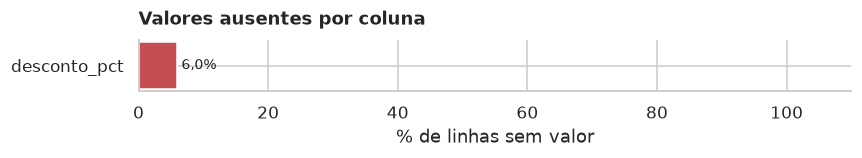

In [9]:
pct_ausentes = df.isna().mean().mul(100)
pct_ausentes = pct_ausentes[pct_ausentes > 0].sort_values().tail(30)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(pct_ausentes) + 1.2))
ax.barh(pct_ausentes.index.astype(str), pct_ausentes.values, color="#C44E52")
for y, valor in enumerate(pct_ausentes.values):
    ax.text(valor, y, f" {formatar_numero(valor, 1)}%", va="center", fontsize=9)
ax.set_xlim(0, 110)
finalizar(ax, "Valores ausentes por coluna", "% de linhas sem valor")
exibir()


### 5.2 Checagens automáticas

Colunas constantes, com muitos ausentes, categorias que só diferem em caixa, acento ou
espaços, poucos valores negativos (erro de digitação?), excesso de categorias,
identificador repetido e valores infinitos. Nada é corrigido automaticamente aqui.


In [10]:
COLS_NUM = ['quantidade', 'preco_unitario', 'desconto_pct', 'valor_total']
COLS_CAT = ['regiao', 'categoria', 'canal', 'vendedor', 'avaliado']
qualidade = checar_qualidade(df, COLS_NUM, COLS_CAT, bruto=df_bruto)
if qualidade.empty:
    print("Nenhum problema encontrado pelas checagens automáticas.")
else:
    display(qualidade)

# Para unificar variantes de categorias, adapte e descomente (e rode as células seguintes de novo):
# df['regiao'] = df['regiao'].str.strip().str.capitalize()


,coluna,problema,detalhe
0,regiao,categorias_parecidas,"""Sudeste"" / ""sudeste"""


## 6. Variáveis numéricas

### 6.1 Estatísticas descritivas

`assimetria` acima de 1 (ou abaixo de −1) indica cauda longa à direita (à esquerda);
`curtose` alta indica valores extremos frequentes.


In [11]:
COLS_DESCRIBE = ['quantidade', 'preco_unitario', 'desconto_pct', 'valor_total']
NOMES = {"count": "n", "mean": "média", "std": "desvio_padrão", "min": "mínimo",
         "25%": "q1", "50%": "mediana", "75%": "q3", "max": "máximo"}

estatisticas = df[COLS_DESCRIBE].describe().T.rename(columns=NOMES)
estatisticas["assimetria"] = df[COLS_DESCRIBE].skew()
estatisticas["curtose"] = df[COLS_DESCRIBE].kurtosis()
estatisticas["ausentes"] = df[COLS_DESCRIBE].isna().sum()
estatisticas.round(2)


,n,média,desvio_padrão,mínimo,q1,mediana,q3,máximo,assimetria,curtose,ausentes
quantidade,50.0,7.12,10.94,1.0,1.00,2.00,6.75,50.0,2.46,5.83,0
preco_unitario,50.0,403.07,648.30,17.9,46.15,124.90,494.22,3499.0,2.86,10.20,0
desconto_pct,47.0,7.52,7.85,0.0,0.00,5.00,12.00,25.0,0.83,-0.38,3
valor_total,50.0,646.54,674.14,89.9,236.21,323.65,841.91,3149.1,1.93,3.62,0


### 6.2 Distribuições

Histogramas; a linha tracejada marca a mediana. Colunas binárias (0/1) e constantes
ficam de fora.


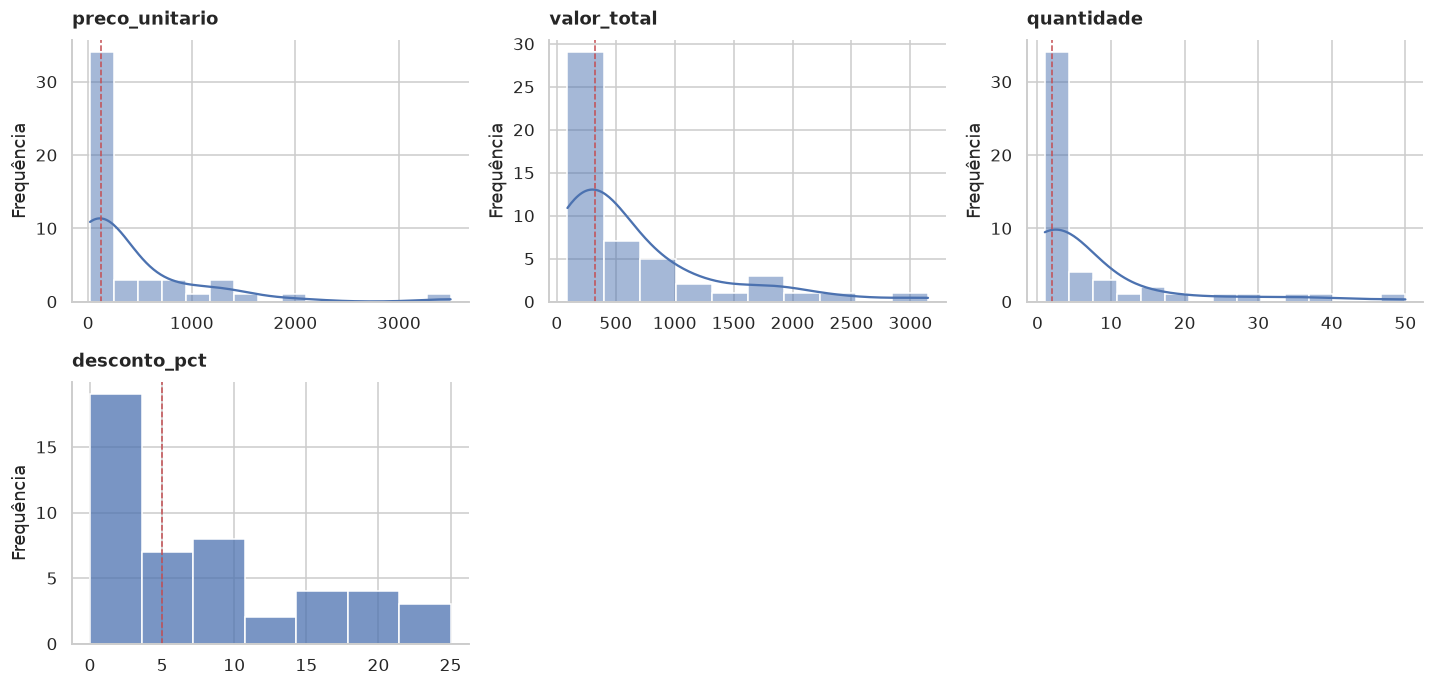

In [12]:
COLS_NUM_GRAFICO = ['preco_unitario', 'valor_total', 'quantidade', 'desconto_pct']
n_colunas = min(3, len(COLS_NUM_GRAFICO))
n_linhas = int(np.ceil(len(COLS_NUM_GRAFICO) / n_colunas))
fig, axes = plt.subplots(n_linhas, n_colunas, figsize=(4.4 * n_colunas, 3.2 * n_linhas),
                         squeeze=False)
for ax in axes.ravel()[len(COLS_NUM_GRAFICO):]:
    ax.set_visible(False)
for ax, coluna in zip(axes.ravel(), COLS_NUM_GRAFICO):
    valores = df[coluna].dropna()
    # Curva de densidade só entre 50 e 50.000 valores (com poucos engana; com muitos é lenta).
    sns.histplot(valores, kde=50 <= len(valores) <= 50_000, ax=ax, color="#4C72B0")
    ax.axvline(valores.median(), color="#C44E52", linestyle="--", linewidth=1)
    finalizar(ax, coluna, "", "Frequência")
exibir()


### 6.3 Outliers

Regra de Tukey: valores abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR. Outlier não
é sinônimo de erro: confira os casos antes de remover qualquer coisa.


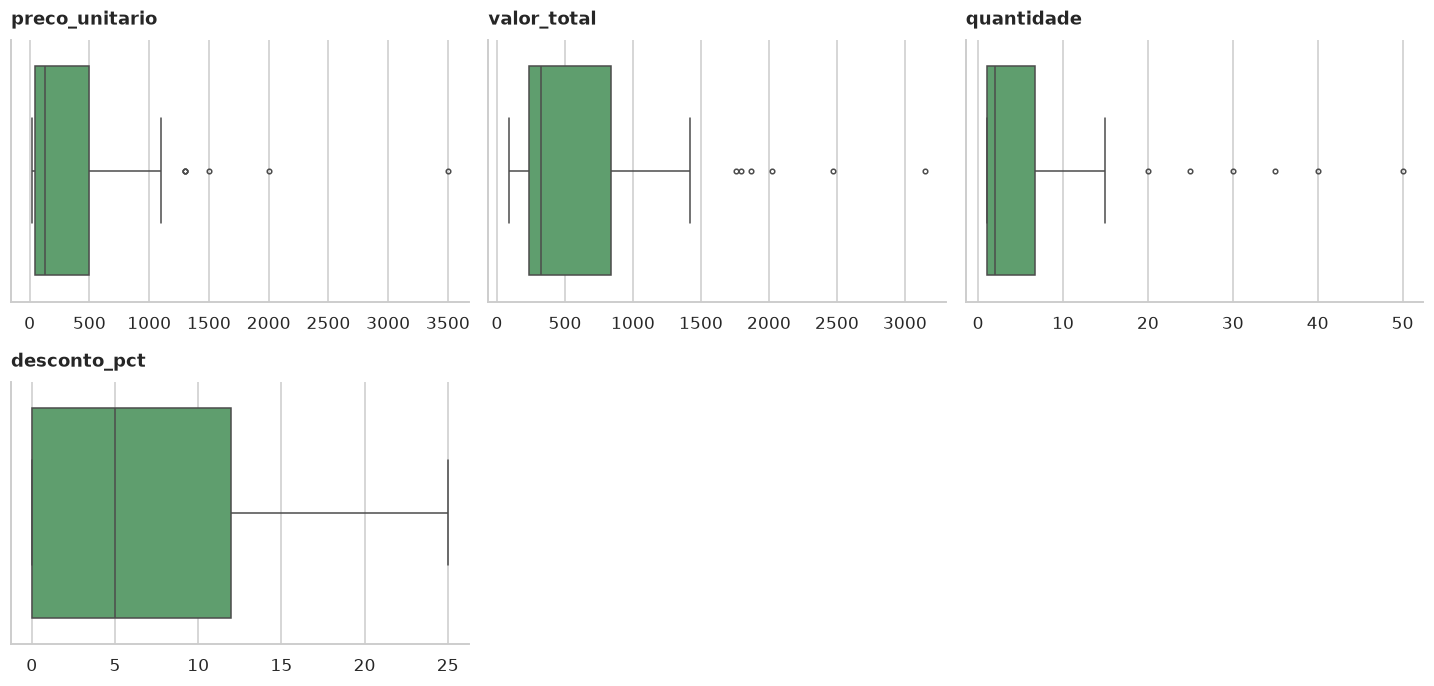

,n_validos,q1,q3,limite_inferior,limite_superior,n_outliers,pct_outliers,minimo,maximo
coluna,,,,,,,,,
preco_unitario,50,46.15,494.22,-625.96,1166.34,6,12.0,17.9,3499.0
valor_total,50,236.21,841.91,-672.34,1750.46,6,12.0,89.9,3149.1
quantidade,50,1.00,6.75,-7.62,15.38,6,12.0,1.0,50.0
desconto_pct,47,0.00,12.00,-18.00,30.00,0,0.0,0.0,25.0


In [13]:
n_colunas = min(3, len(COLS_NUM_GRAFICO))
n_linhas = int(np.ceil(len(COLS_NUM_GRAFICO) / n_colunas))
fig, axes = plt.subplots(n_linhas, n_colunas, figsize=(4.4 * n_colunas, 3.2 * n_linhas),
                         squeeze=False)
for ax in axes.ravel()[len(COLS_NUM_GRAFICO):]:
    ax.set_visible(False)
for ax, coluna in zip(axes.ravel(), COLS_NUM_GRAFICO):
    sns.boxplot(x=df[coluna].dropna(), ax=ax, color="#55A868", fliersize=3)
    finalizar(ax, coluna)
exibir()

display(tabela_outliers(df, COLS_NUM_GRAFICO).round(2))


## 7. Variáveis categóricas

### 7.1 Frequências

As 15 categorias mais comuns de cada coluna; o restante é somado em "(outras)".


In [14]:
COLS_FREQ = ['regiao', 'categoria', 'canal', 'vendedor', 'avaliado']
for coluna in COLS_FREQ:
    contagem = df[coluna].value_counts(dropna=False)
    tabela = contagem.head(15).to_frame("registros")
    if len(contagem) > 15:
        tabela.loc["(outras)"] = contagem.iloc[15:].sum()
    tabela["%"] = (100 * tabela["registros"] / len(df)).round(1)
    print(f"{coluna}: {df[coluna].nunique()} valores distintos")
    display(tabela)


regiao: 5 valores distintos


,registros,%
regiao,,
Sudeste,13,26.0
Sul,13,26.0
Nordeste,12,24.0
Centro-Oeste,11,22.0
sudeste,1,2.0


categoria: 4 valores distintos


,registros,%
categoria,,
Eletrônicos,15,30.0
Vestuário,13,26.0
Alimentos,12,24.0
Livros,10,20.0


canal: 2 valores distintos


,registros,%
canal,,
Online,27,54.0
Loja física,23,46.0


vendedor: 4 valores distintos


,registros,%
vendedor,,
Ana Souza,14,28.0
Carlos Lima,13,26.0
Marina Alves,12,24.0
Pedro Alves,11,22.0


avaliado: 2 valores distintos


,registros,%
avaliado,,
Sim,36,72.0
Não,14,28.0


### 7.2 Gráficos de frequência


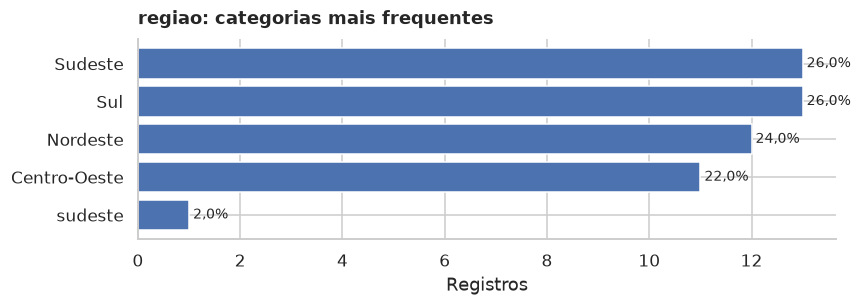

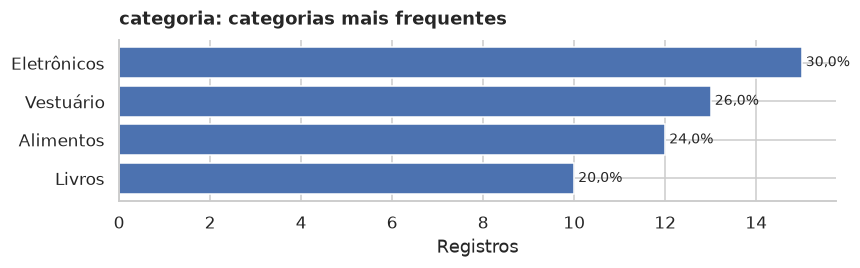

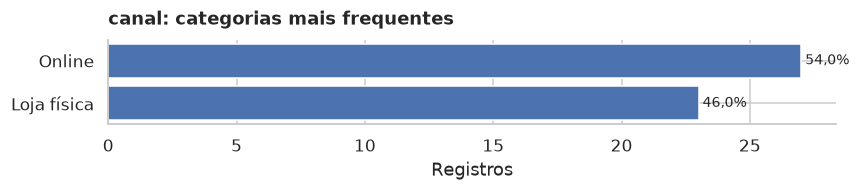

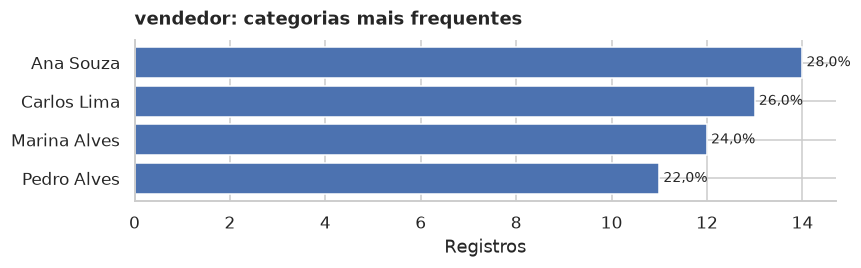

In [15]:
COLS_CAT_GRAFICO = ['regiao', 'categoria', 'canal', 'vendedor']
for coluna in COLS_CAT_GRAFICO:
    contagem = df[coluna].value_counts().head(15).sort_values()
    total = df[coluna].notna().sum()
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(contagem) + 1.2))
    ax.barh(contagem.index.astype(str), contagem.values, color="#4C72B0")
    for y, valor in enumerate(contagem.values):
        ax.text(valor, y, f" {formatar_numero(100 * valor / total, 1)}%", va="center", fontsize=9)
    finalizar(ax, f"{coluna}: categorias mais frequentes", "Registros")
    exibir()


## 8. Correlação entre numéricas

Pearson (`r`) mede relação linear; Spearman (`rho`) mede relação monotônica e é menos
sensível a outliers. Força pelo maior dos dois, em módulo: abaixo de 0,1 desprezível,
0,1 fraca, 0,3 moderada, 0,5 forte, 0,7 ou mais muito forte. Correlação não indica
causa.


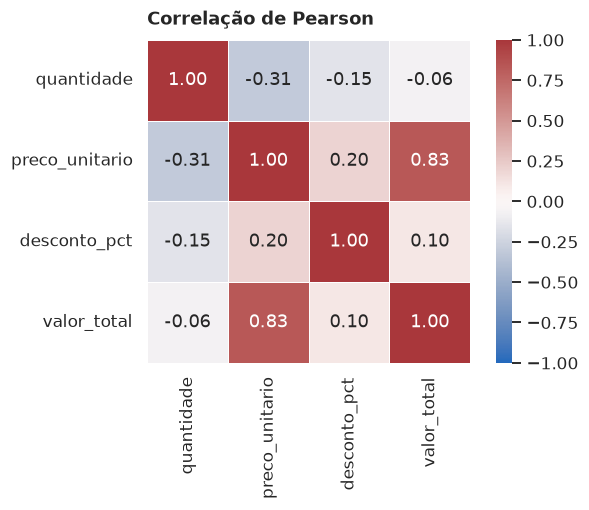

,variável_a,variável_b,r,rho,n,força
4,preco_unitario,valor_total,0.832,0.440,50,muito forte
0,quantidade,preco_unitario,-0.311,-0.814,50,muito forte
3,preco_unitario,desconto_pct,0.200,0.255,47,fraca
1,quantidade,desconto_pct,-0.153,-0.137,47,fraca
5,desconto_pct,valor_total,0.104,0.093,47,fraca
2,quantidade,valor_total,-0.065,0.070,50,desprezível


In [16]:
COLS_CORR = ['quantidade', 'preco_unitario', 'desconto_pct', 'valor_total']
# Pares com menos de 10 linhas preenchidas em comum ficam em branco.
pearson = df[COLS_CORR].corr(method="pearson", min_periods=10)
spearman = df[COLS_CORR].corr(method="spearman", min_periods=10)

fig, ax = plt.subplots(figsize=(0.8 * len(COLS_CORR) + 3, 0.7 * len(COLS_CORR) + 2))
sns.heatmap(pearson, annot=len(COLS_CORR) <= 12, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
finalizar(ax, "Correlação de Pearson")
exibir()

pares = []
for i, a in enumerate(COLS_CORR):
    for b in COLS_CORR[i + 1:]:
        r, rho = pearson.loc[a, b], spearman.loc[a, b]
        pares.append({"variável_a": a, "variável_b": b, "r": r, "rho": rho,
                      "n": len(df[[a, b]].dropna()),
                      "força": classificar_correlacao(rho if abs(rho) > abs(r) else r)})
tabela_corr = pd.DataFrame(pares)
ordem = tabela_corr[["r", "rho"]].abs().max(axis=1).sort_values(ascending=False).index
tabela_corr.loc[ordem].head(15).round(3)


## 9. Numéricas por categoria

Pares escolhidos pela maior diferença entre grupos, medida pelo eta²: a fração da
variância da numérica explicada pela categoria (0 a 1; só grupos com 5 ou mais
registros). Como referência, 0,01 é pequeno, 0,06 médio e 0,14 grande.


In [17]:
PARES = [('categoria', 'valor_total'), ('categoria', 'quantidade'), ('vendedor', 'quantidade')]
for categoria, numerica in PARES:
    tabela = (
        df.groupby(categoria)[numerica]
        .agg(n="count", média="mean", mediana="median", desvio_padrão="std",
             mínimo="min", máximo="max")
        .sort_values("mediana", ascending=False)
    )
    eta2 = eta_quadrado(df, categoria, numerica)
    print(f"{numerica} por {categoria}: eta² = {formatar_numero(eta2) if eta2 is not None else '—'}")
    display(tabela.round(2))


valor_total por categoria: eta² = 0,65


,n,média,mediana,desvio_padrão,mínimo,máximo
categoria,,,,,,
Eletrônicos,15,1453.55,1234.90,723.65,597.08,3149.10
Alimentos,12,446.38,379.36,198.82,220.00,805.50
Vestuário,13,257.22,269.70,79.09,134.93,393.27
Livros,10,182.35,170.74,76.39,89.90,324.50


quantidade por categoria: eta² = 0,64


,n,média,mediana,desvio_padrão,mínimo,máximo
categoria,,,,,,
Alimentos,12,22.50,17.5,13.59,8,50
Livros,10,3.40,3.5,2.17,1,7
Vestuário,13,1.92,2.0,0.95,1,4
Eletrônicos,15,1.80,1.0,1.26,1,5


quantidade por vendedor: eta² = 0,23


,n,média,mediana,desvio_padrão,mínimo,máximo
vendedor,,,,,,
Carlos Lima,13,15.69,10.0,17.43,1,50
Ana Souza,14,5.43,2.5,6.87,1,25
Pedro Alves,11,3.55,2.0,3.88,1,15
Marina Alves,12,3.08,1.5,3.32,1,12


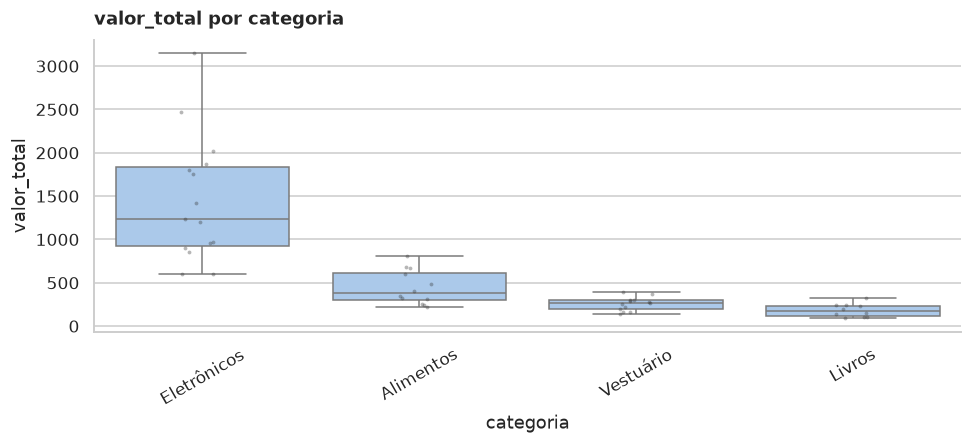

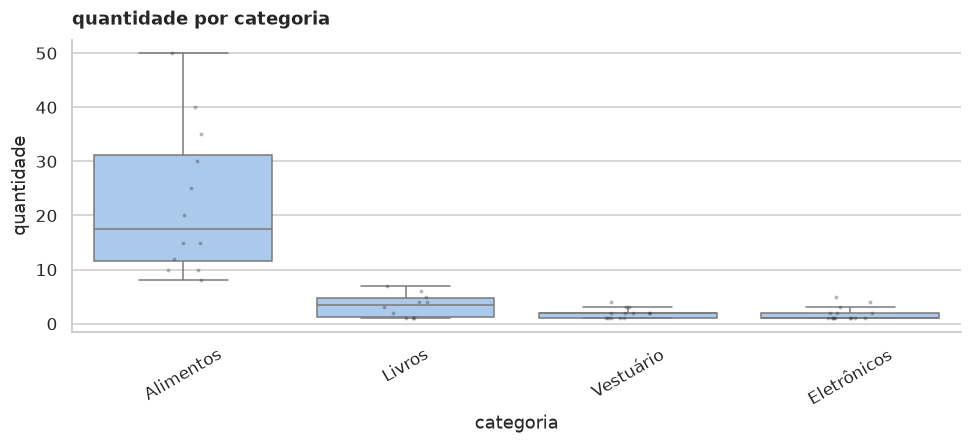

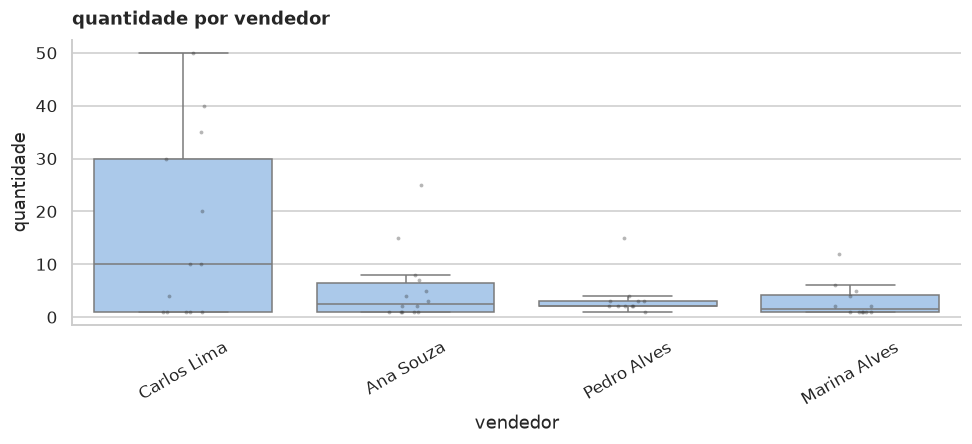

In [18]:
for categoria, numerica in PARES:
    base = df[[categoria, numerica]].dropna()
    ordem = base.groupby(categoria)[numerica].median().sort_values(ascending=False).index[:8]
    base = base[base[categoria].isin(ordem)]
    # Os pontos individuais usam no máximo 2.000 linhas (amostra fixa), por legibilidade.
    pontos = base if len(base) <= 2000 else base.sample(2000, random_state=0)
    nota = "" if len(pontos) == len(base) else f" (pontos: amostra de 2.000 de {len(base)})"

    fig, ax = plt.subplots(figsize=(9, 4.2))
    sns.boxplot(data=base, x=categoria, y=numerica, order=ordem, ax=ax,
                color="#A1C9F4", fliersize=0)
    sns.stripplot(data=pontos, x=categoria, y=numerica, order=ordem, ax=ax,
                  color="#2F2F2F", alpha=0.35, size=2.5)
    finalizar(ax, f"{numerica} por {categoria}{nota}", categoria, numerica)
    ax.tick_params(axis="x", labelrotation=30)
    exibir()


## 10. Relação entre categóricas

Par de categóricas mais associado pelo V de Cramér (0 = independentes, 1 = associação
total): contagens e composição de `vendedor` dentro de cada valor de `regiao`.


V de Cramér entre regiao e vendedor: 0,61


vendedor,Ana Souza,Carlos Lima,Marina Alves,Pedro Alves,(total)
regiao,,,,,
Centro-Oeste,2,2,0,7,11
Nordeste,1,2,9,0,12
Sudeste,10,2,1,0,13
Sul,0,7,2,4,13
sudeste,1,0,0,0,1
(total),14,13,12,11,50


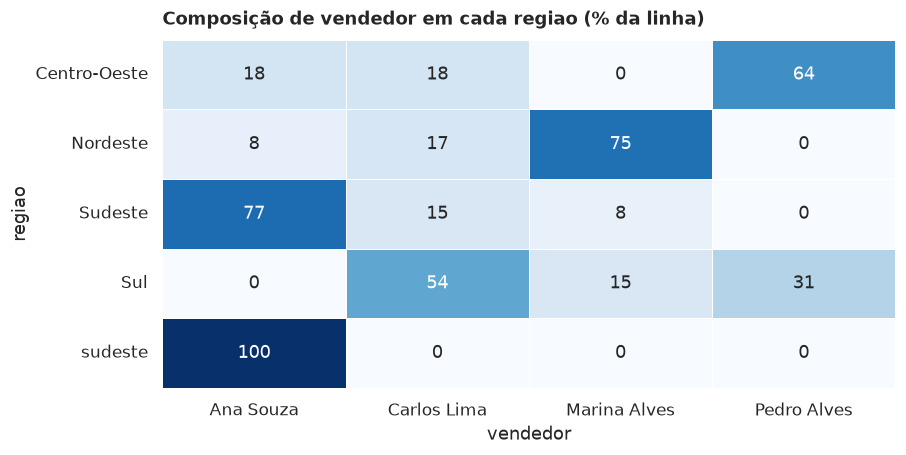

In [19]:
A, B = 'regiao', 'vendedor'
print(f"V de Cramér entre {A} e {B}: {formatar_numero(v_de_cramer(df, A, B))}")
display(pd.crosstab(df[A], df[B], margins=True, margins_name="(total)"))

proporcao = pd.crosstab(df[A], df[B], normalize="index").mul(100)
fig, ax = plt.subplots(figsize=(1.1 * proporcao.shape[1] + 4, 0.5 * proporcao.shape[0] + 1.8))
sns.heatmap(proporcao, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5, cbar=False, ax=ax)
finalizar(ax, f"Composição de {B} em cada {A} (% da linha)", B, A)
exibir()


## 11. Evolução temporal

Registros e média das numéricas por período (`data_pedido` por mês). A periodicidade fica em
`REGRAS` e pode ser trocada. Períodos sem registros aparecem como lacunas.


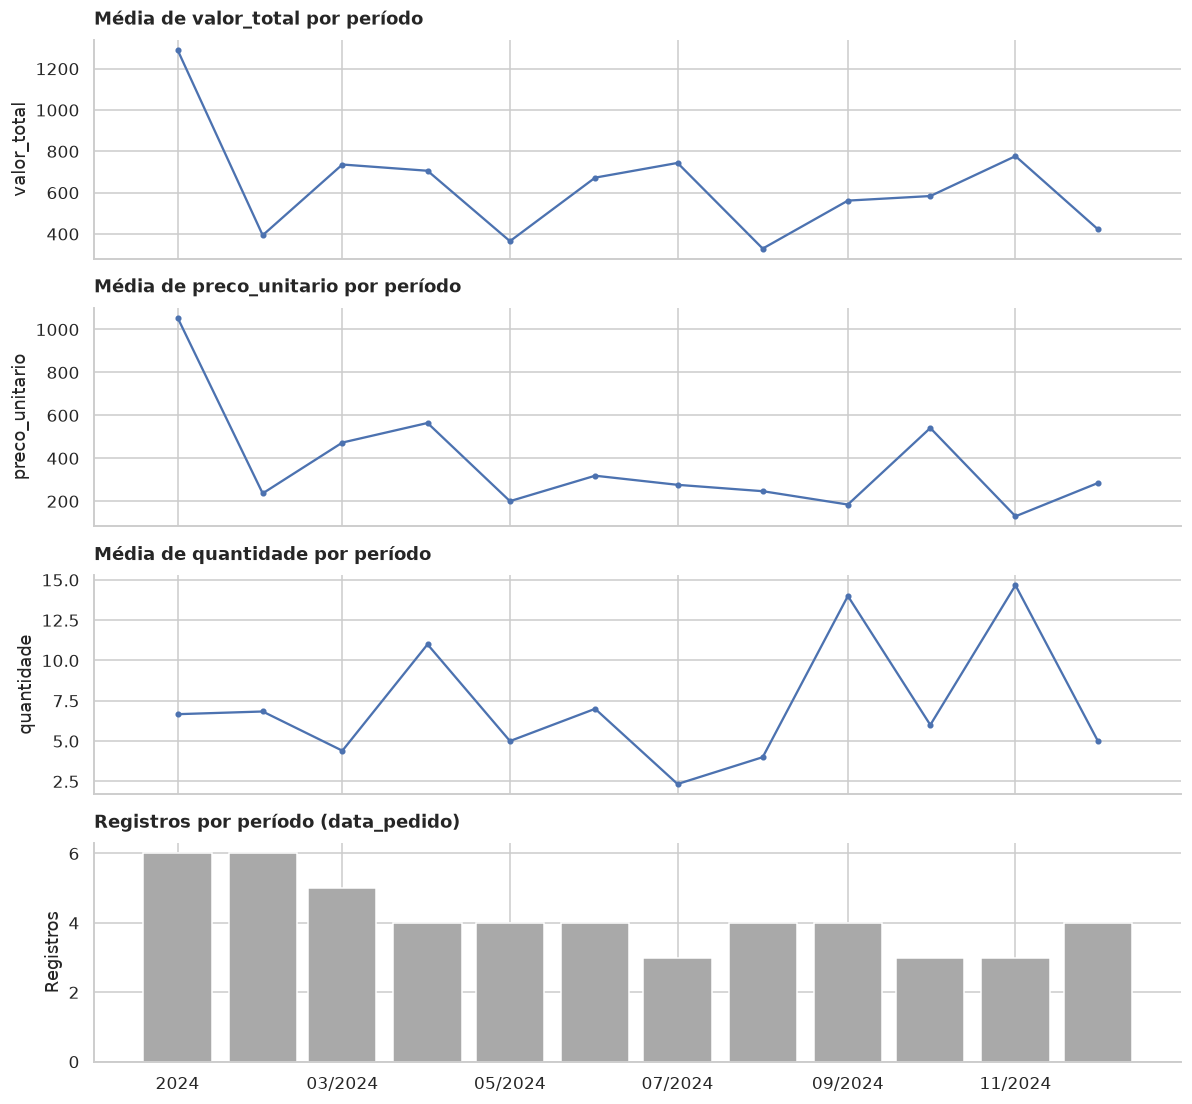

,registros,valor_total,preco_unitario,quantidade
período,,,,
01/2024,6,1291.30,1055.52,6.67
02/2024,6,393.61,236.42,6.83
03/2024,5,736.09,473.14,4.40
04/2024,4,705.83,564.33,11.00
05/2024,4,365.00,200.18,5.00
06/2024,4,672.52,318.70,7.00
07/2024,3,743.71,276.27,2.33
08/2024,4,329.12,246.58,4.00
09/2024,4,561.36,184.40,14.00


In [20]:
# Periodicidade por coluna de data: D = dia, W = semana, MS = mês, QS = trimestre, YS = ano.
REGRAS = {'data_pedido': 'MS'}
COLS_SERIE = ['valor_total', 'preco_unitario', 'quantidade']
FORMATO_PERIODO = {"D": "%d/%m/%Y", "W": "%d/%m/%Y", "MS": "%m/%Y", "QS": "%m/%Y", "YS": "%Y"}

for coluna_data, regra in REGRAS.items():
    base = df.dropna(subset=[coluna_data]).set_index(coluna_data).sort_index()
    contagem = base.resample(regra).size()
    medias = base[COLS_SERIE].resample(regra).mean()

    paineis = len(COLS_SERIE) + 1
    fig, axes = plt.subplots(paineis, 1, figsize=(11, 2.4 * paineis + 0.6), sharex=True,
                             squeeze=False)
    axes = axes.ravel()
    for ax, coluna in zip(axes, COLS_SERIE):
        # Períodos sem registros ficam como lacunas na linha.
        ax.plot(medias.index, medias[coluna], marker="o", markersize=3, linewidth=1.5)
        finalizar(ax, f"Média de {coluna} por período", "", coluna)
    largura = 0.8 * (contagem.index.to_series().diff().dt.days.median() if len(contagem) > 1 else 1)
    axes[-1].bar(contagem.index, contagem.values, width=largura, color="#A9A9A9")
    finalizar(axes[-1], f"Registros por período ({coluna_data})", "", "Registros")
    formatar_eixo_datas(axes[-1])
    exibir()

    tabela = medias.round(2)
    tabela.insert(0, "registros", contagem, allow_duplicates=True)
    tabela.index = tabela.index.strftime(FORMATO_PERIODO[regra])
    tabela.index.name = "período"
    if len(tabela) > 36:
        print(f"Últimos 36 de {len(tabela)} períodos:")
    display(tabela.tail(36))


## 12. Variável de interesse: `valor_total`

Distribuição, correlação com as demais numéricas e média por categoria (categorias que mais diferenciam o alvo). Associação não é causa.


,count,mean,std,min,25%,50%,75%,max
valor_total,50.0,646.54,674.14,89.9,236.21,323.65,841.91,3149.1


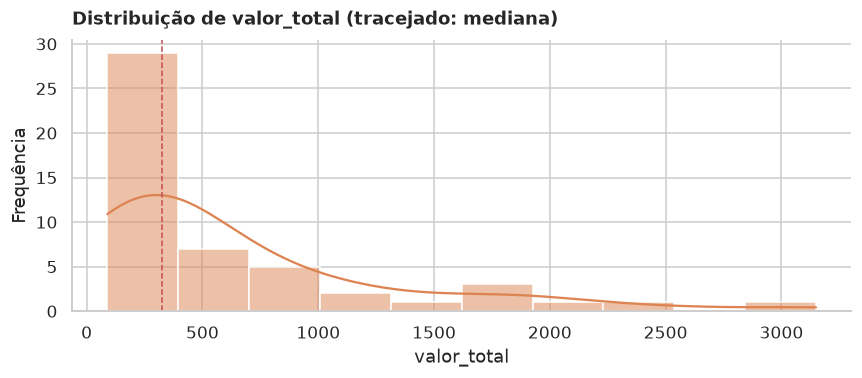

In [21]:
valores = df[ALVO].dropna()
display(valores.describe().to_frame().T.round(2))

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(valores, kde=50 <= len(valores) <= 50_000, ax=ax, color="#DD8452")
ax.axvline(valores.median(), color="#C44E52", linestyle="--", linewidth=1)
finalizar(ax, f"Distribuição de {ALVO} (tracejado: mediana)", ALVO, "Frequência")
exibir()


In [22]:
COLS_CORR_ALVO = ['quantidade', 'preco_unitario', 'desconto_pct']
base = df[[ALVO] + COLS_CORR_ALVO]
correlacoes = pd.DataFrame({
    "r": base.corr(method="pearson", min_periods=10)[ALVO].drop(ALVO),
    "rho": base.corr(method="spearman", min_periods=10)[ALVO].drop(ALVO),
    "n": [len(df[[ALVO, coluna]].dropna()) for coluna in COLS_CORR_ALVO],
})
correlacoes["força"] = [classificar_correlacao(rho if abs(rho) > abs(r) else r)
                        for r, rho in zip(correlacoes["r"], correlacoes["rho"])]
correlacoes.sort_values("rho", key=abs, ascending=False).round(3)


,r,rho,n,força
preco_unitario,0.832,0.440,50,muito forte
desconto_pct,0.104,0.093,47,fraca
quantidade,-0.065,0.070,50,desprezível


,n,média,mediana
categoria,,,
Eletrônicos,15,1453.55,1234.90
Alimentos,12,446.38,379.36
Vestuário,13,257.22,269.70
Livros,10,182.35,170.74


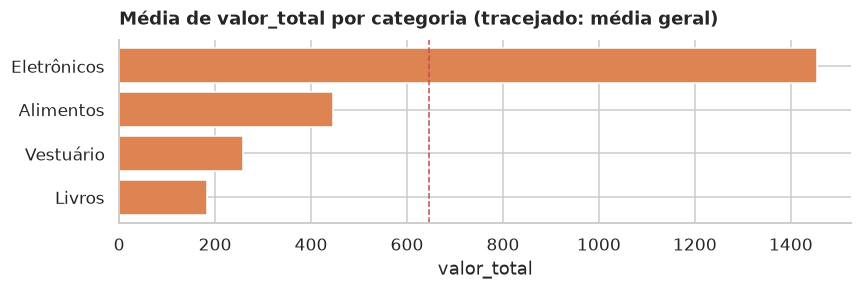

,n,média,mediana
vendedor,,,
Ana Souza,14,908.42,670.80
Carlos Lima,13,895.38,672.00
Pedro Alves,11,452.24,299.80
Marina Alves,12,249.56,176.55


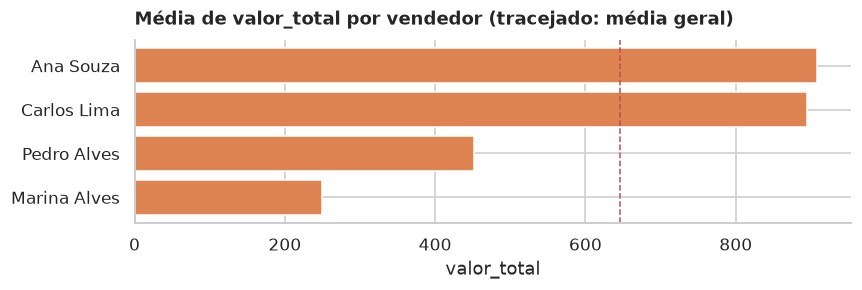

In [23]:
CATS_ALVO = ['categoria', 'vendedor']
for categoria in CATS_ALVO:
    tabela = (df.groupby(categoria)[ALVO]
                .agg(n="count", média="mean", mediana="median")
                .sort_values("média"))
    display(tabela.iloc[::-1].round(2))
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(tabela) + 1.2))
    ax.barh(tabela.index.astype(str), tabela["média"], color="#DD8452")
    ax.axvline(df[ALVO].mean(), color="#C44E52", linestyle="--", linewidth=1)
    finalizar(ax, f"Média de {ALVO} por {categoria} (tracejado: média geral)", ALVO)
    exibir()


## 13. Resumo

Calculado na geração do notebook, com as mesmas funções de limpeza. Se você mudar o
notebook, este texto não se atualiza sozinho.


### Visão geral

- **Arquivo:** `vendas_exemplo.csv`
- **Dimensões (após a limpeza):** 50 linhas × 11 colunas
- **Tipos:** 4 numéricas, 5 categóricas, 1 data, 0 colunas de texto livre.
- **Identificadores (fora das análises):** `id_venda`.
- **Valores ausentes:** 0,5% das células; mais afetadas: `desconto_pct` (6,0%).
- **Período coberto:** 05/01/2024 a 29/12/2024 (359 dias).

### Principais achados

- Maior correlação de `valor_total`: com `preco_unitario`, rho = 0,44, r = 0,83 (muito forte, positiva; n = 50).
- Média de `valor_total` por `categoria`: maior em `Eletrônicos` (1.453,55; n = 15) e menor em `Livros` (182,35; n = 10).
- `quantidade` × `preco_unitario`: rho = -0,81, r = -0,31 (muito forte, negativa; n = 50); a diferença entre rho e r sugere relação monotônica não linear ou influência de outliers.
- `quantidade` por `categoria`: mediana mais alta em `Alimentos` (17,50; n = 12) e mais baixa em `Eletrônicos` (1,00; n = 15); 17,5 vezes a menor; eta² = 0,64.
- `quantidade` por `vendedor`: mediana mais alta em `Carlos Lima` (10,00; n = 13) e mais baixa em `Marina Alves` (1,50; n = 12); 6,7 vezes a menor; eta² = 0,23.
- Por mês (`data_pedido`), do primeiro ao último período completo (02/2024 → 11/2024): registros de 6 para 3 (-50,0%); média de `valor_total` de 393,61 para 776,64 (+97,3%).
- `preco_unitario`: mediana 124,90 (de 17,90 a 3.499,00); cauda longa à direita (assimetria = 2,86).
- `valor_total`: mediana 323,65 (de 89,90 a 3.149,10); cauda longa à direita (assimetria = 1,93).
- `quantidade`: mediana 2,00 (de 1,00 a 50,00); cauda longa à direita (assimetria = 2,46).
- Mais outliers pela regra de 1,5 × IQR: `preco_unitario` 12,0% (6 valores), `valor_total` 12,0% (6 valores).
- `regiao`: 5 categorias; a mais frequente é `Sudeste` (26,0% dos registros preenchidos).
- `categoria`: 4 categorias; a mais frequente é `Eletrônicos` (30,0% dos registros preenchidos).

### Pontos de atenção

- `regiao`: categorias que só diferem em caixa, acento ou espaços — "Sudeste" / "sudeste".
- 1 duplicata removida (linhas idênticas a uma anterior).

### Próximos passos sugeridos

1. Unificar as variantes de `regiao` (há um exemplo comentado na seção de qualidade) e rodar o notebook de novo.
2. Conferir os valores extremos de `preco_unitario`: erro de registro ou casos reais? A tabela da seção de outliers traz os limites.
